# Import packages & Load functions and data

In [ ]:
import math
import pysam
import glob, os
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [11]:
def getReadLevelVariantInfo( PATH_bam, variants_of_interest, ):
    bamfile = pysam.AlignmentFile(PATH_bam ,'rb')
    ReadLevelVariantInfo = list()

    for variant_entry in variants_of_interest.itertuples():
        chrom, variant_position, variant_type = variant_entry.chrom, variant_entry.pos, variant_entry.variant_type
        reference_allele, mutant_allele = variant_entry.ref, variant_entry.alt
        for pileupcolumn in bamfile.pileup( chrom, variant_position-1, variant_position, truncate=True ):
            for pileupread in pileupcolumn.pileups:
                if pileupread.is_del==False and pileupread.is_refskip==False and pileupread.alignment.is_supplementary==False and pileupread.alignment.is_secondary==False:
                    read_allele = pileupread.alignment.query_sequence[pileupread.query_position]
                    ReadLevelVariantInfo.append( [chrom, variant_position, variant_type, pileupread.alignment.query_name, read_allele, reference_allele, mutant_allele ] )

    ReadLevelVariantInfo = pd.DataFrame(ReadLevelVariantInfo, columns=['chrom', 'pos', 'variant_type', 'readname', 'read_allele', 'ref_allele', 'alt_allele'])

    ReadLevelVariantInfo_organized = list()
    for readname, edf in ReadLevelVariantInfo.groupby('readname'):
        # if len(edf)!=4: continue 
        if len(edf)!=len(variants_of_interest): continue 

        dict_pos_to_alleleInfo = dict()
        for tup in edf.itertuples(): dict_pos_to_alleleInfo[tup.pos] = [ tup.variant_type, tup.read_allele, tup.ref_allele, tup.alt_allele ]

        for variant in variants_of_interest.itertuples():
            ReadLevelVariantInfo_organized.append( [readname, variant.chrom, variant.pos, 
                                                    dict_pos_to_alleleInfo[variant.pos][0], dict_pos_to_alleleInfo[variant.pos][1], dict_pos_to_alleleInfo[variant.pos][2], dict_pos_to_alleleInfo[variant.pos][3]] )
    ReadLevelVariantInfo_organized = pd.DataFrame(ReadLevelVariantInfo_organized, columns=['readname', 'chrom', 'pos', 'variant_type', 'read_allele', 'ref_allele', 'alt_allele'])

    return ReadLevelVariantInfo, ReadLevelVariantInfo_organized

In [4]:
DIR_data = f'/home/18parkky/data/aml/paper'

PATH_ONT_total_variants_clnsig_updated = f'{DIR_data}/final_vcfs/AML_ONT_annotated_variants_total.clnsig_updated.tsv.gz'
ONT_variants = pd.read_csv(PATH_ONT_total_variants_clnsig_updated, sep='\t')

/tmp/ipykernel_2557740/2649451167.py:4: DtypeWarning: Columns (17) have mixed types. Specify dtype option on import or set low_memory=False.
  ONT_variants = pd.read_csv(PATH_ONT_total_variants_clnsig_updated, sep='\t')


# Find adjacent mutation pairs

In [7]:
ONT_relevant_variants = pd.read_csv(f'{DIR_data}/final_vcfs/AML_ONT_annotated_variants_total.clnsig_updated.deleterious.tsv.gz', sep='\t', )
ONT_relevant_variants.reset_index(inplace=True, drop=True)
ONT_relevant_variants.columns = [ 'chrom' ] + list(ONT_relevant_variants.columns)[1:]

In [10]:
def get_distance_between_variants( variants ):
    max_p, min_p = max(list(variants['POS'])), min(list(variants['POS']))
    return abs(max_p-min_p)

for SampleID, ONT_variants_clinvar_s_SampleID in ONT_relevant_variants.groupby('SampleID'):
    for chrom, ONT_variants_clinvar_s_SampleID_chrom in ONT_variants_clinvar_s_SampleID.groupby('chrom'):
        if len(ONT_variants_clinvar_s_SampleID_chrom)>=2:
            print(f'{SampleID} {chrom}\t{ONT_variants_clinvar_s_SampleID_chrom.iloc[0].GeneName}\t{len(ONT_variants_clinvar_s_SampleID_chrom)}\t{get_distance_between_variants(ONT_variants_clinvar_s_SampleID_chrom)}')

barcode13 chr17	TP53	2	1142
barcode15 chr12	ETV6	2	45307
barcode17 chr21	RUNX1	2	67192
barcode37 chr16	CREBBP	2	63300298
barcode37 chr21	RUNX1	2	8235191
barcode46 chr17	TP53	2	2217
barcode50 chr21	RUNX1	2	88189
barcode61 chr17	TP53	2	1338
barcode63 chr17	SRSF2	2	69060490


## barcode13, chr17, TP53

In [14]:
PATH_BAM = '/data01/node200data/18parkky/datasets/data/FGL/FASTQ/AML_TS_Run1_241223_sup/minimap2_out/barcode13.sorted.bam'

variants_of_interest = [['chr17', 7673811, 'A', 'G', 'pathogenic'], 
                        ['chr17', 7674953, 'T', 'C', 'pathogenic'], 
                        ['chr17', 7673030, 'C', 'T', 'germline'], 
                        ['chr17', 7675361, 'A', 'G', 'germline'], # manually found through IGV
                        ]
variants_of_interest = pd.DataFrame(variants_of_interest, columns=['chrom', 'pos', 'ref', 'alt', 'variant_type'])
bc13_chr17_ReadLevelVariantInfo, bc13_chr17_ReadLevelVariantInfo_organized = getReadLevelVariantInfo(PATH_BAM, variants_of_interest)
bc13_chr17_ReadLevelVariantInfo_organized['isMut'] = bc13_chr17_ReadLevelVariantInfo_organized['read_allele']==bc13_chr17_ReadLevelVariantInfo_organized['alt_allele']
bc13_chr17_ReadLevelVariantInfo['Identifier'] = [ f'{tup.chrom}:{tup.pos}:{tup.ref_allele}>{tup.alt_allele}:{tup.variant_type}' for tup in bc13_chr17_ReadLevelVariantInfo.itertuples() ]
bc13_chr17_ReadLevelVariantInfo_organized['Identifier'] = [ f'{tup.chrom}:{tup.pos}:{tup.ref_allele}>{tup.alt_allele}:{tup.variant_type}' for tup in bc13_chr17_ReadLevelVariantInfo_organized.itertuples() ]

bc13_chr17_ReadLevelVariantInfo_organized.head(4)

,readname,chrom,pos,variant_type,read_allele,ref_allele,alt_allele,isMut,Identifier
0,0100bd6e-1d6a-4669-a17f-00d1127cd122,chr17,7673811,pathogenic,A,A,G,False,chr17:7673811:A>G:pathogenic
1,0100bd6e-1d6a-4669-a17f-00d1127cd122,chr17,7674953,pathogenic,C,T,C,True,chr17:7674953:T>C:pathogenic
2,0100bd6e-1d6a-4669-a17f-00d1127cd122,chr17,7673030,germline,T,C,T,True,chr17:7673030:C>T:germline
3,0100bd6e-1d6a-4669-a17f-00d1127cd122,chr17,7675361,germline,G,A,G,True,chr17:7675361:A>G:germline


In [16]:
bc13_chr17_ReadLevelVariantInfo_heatmap = bc13_chr17_ReadLevelVariantInfo_organized.pivot(index='readname', columns='Identifier', values='isMut')

sorted_variants = sorted(set(bc13_chr17_ReadLevelVariantInfo_organized['Identifier']), key=lambda x: ( x.endswith(":pathogenic"), int(x.split(":")[1])))
for idx, variant in enumerate(sorted_variants):
    bc13_chr17_ReadLevelVariantInfo_heatmap[variant] = bc13_chr17_ReadLevelVariantInfo_heatmap[variant].replace({True : idx+1, False: 0})

/tmp/ipykernel_2557740/2847502248.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bc13_chr17_ReadLevelVariantInfo_heatmap[variant] = bc13_chr17_ReadLevelVariantInfo_heatmap[variant].replace({True : idx+1, False: 0})


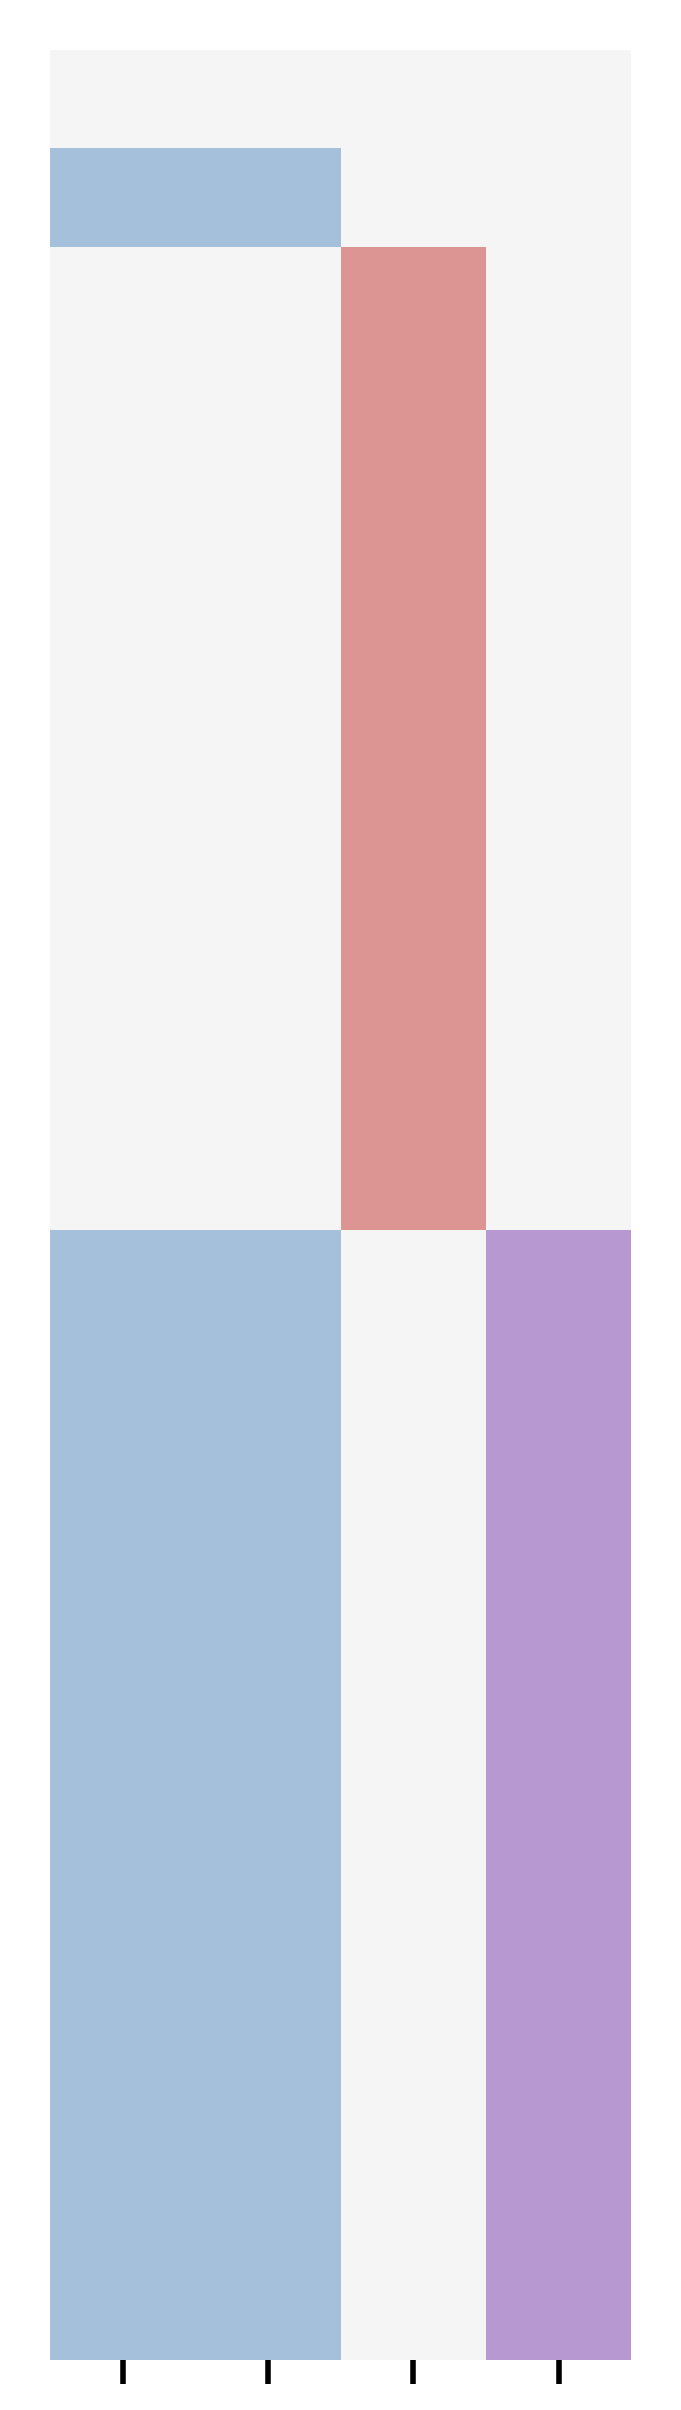

In [19]:
bc13_chr17_ReadLevelVariantInfo_heatmap = bc13_chr17_ReadLevelVariantInfo_heatmap[sorted_variants]
# cmap_e = ListedColormap(["whitesmoke", "cornflowerblue", "lightcoral", "mediumpurple"])
cmap_e = ListedColormap(["whitesmoke", "#A5C0DA", "#A5C0DA", "#DC9592", "#B898D0"])

plt.figure(figsize=(1.5, 6), dpi=500);
ax = sns.heatmap(bc13_chr17_ReadLevelVariantInfo_heatmap.sort_values(sorted_variants[::-1]), 
                 cmap=cmap_e, cbar=False,)
ax.set_yticklabels([]);
ax.set_yticks([]);
ax.set_xticklabels([]);
ax.set_xlabel('');
ax.set_ylabel('');
# ax.set_xticklabels(['Germline', 'Pathogenic A', 'Pathogenic B']);

## barcode46, chr17, TP53

In [20]:
PATH_BAM = '/data01/node200data/18parkky/datasets/data/FGL/FASTQ/AML_TS_Run2_250805_sup/minimap2_out/barcode46.sorted.bam'

variants_of_interest = [['chr17', 7673778, 'T', 'A', 'pathogenic'], 
                        ['chr17', 7675995, 'G', 'A', 'pathogenic'], 
                        # ['chr17', 7672958, 'T', 'A', 'germline'], 
                        ['chr17', 7677182, 'C', 'T', 'germline'],   # manually found through IGV

                        ]
variants_of_interest = pd.DataFrame(variants_of_interest, columns=['chrom', 'pos', 'ref', 'alt', 'variant_type'])
bc46_chr17_ReadLevelVariantInfo, bc46_chr17_ReadLevelVariantInfo_organized = getReadLevelVariantInfo(PATH_BAM, variants_of_interest)
bc46_chr17_ReadLevelVariantInfo_organized['isMut'] = bc46_chr17_ReadLevelVariantInfo_organized['read_allele']==bc46_chr17_ReadLevelVariantInfo_organized['alt_allele']
bc46_chr17_ReadLevelVariantInfo['Identifier'] = [ f'{tup.chrom}:{tup.pos}:{tup.ref_allele}>{tup.alt_allele}:{tup.variant_type}' for tup in bc46_chr17_ReadLevelVariantInfo.itertuples() ]
bc46_chr17_ReadLevelVariantInfo_organized['Identifier'] = [ f'{tup.chrom}:{tup.pos}:{tup.ref_allele}>{tup.alt_allele}:{tup.variant_type}' for tup in bc46_chr17_ReadLevelVariantInfo_organized.itertuples() ]

bc46_chr17_ReadLevelVariantInfo_organized.head(4)

,readname,chrom,pos,variant_type,read_allele,ref_allele,alt_allele,isMut,Identifier
0,016857c4-5ca5-4dff-94ad-da525d3ae245,chr17,7673778,pathogenic,A,T,A,True,chr17:7673778:T>A:pathogenic
1,016857c4-5ca5-4dff-94ad-da525d3ae245,chr17,7675995,pathogenic,G,G,A,False,chr17:7675995:G>A:pathogenic
2,016857c4-5ca5-4dff-94ad-da525d3ae245,chr17,7677182,germline,T,C,T,True,chr17:7677182:C>T:germline
3,01f0bd52-a8b5-4388-ba21-aa69f52190d0,chr17,7673778,pathogenic,A,T,A,True,chr17:7673778:T>A:pathogenic


In [22]:
bc46_chr17_ReadLevelVariantInfo_heatmap = bc46_chr17_ReadLevelVariantInfo_organized.pivot(index='readname', columns='Identifier', values='isMut')

sorted_variants = sorted(set(bc46_chr17_ReadLevelVariantInfo_organized['Identifier']), key=lambda x: ( x.endswith(":pathogenic"), int(x.split(":")[1])))
for idx, variant in enumerate(sorted_variants):
    bc46_chr17_ReadLevelVariantInfo_heatmap[variant] = bc46_chr17_ReadLevelVariantInfo_heatmap[variant].replace({True : idx+1, False: 0})

/tmp/ipykernel_2557740/3199063896.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bc46_chr17_ReadLevelVariantInfo_heatmap[variant] = bc46_chr17_ReadLevelVariantInfo_heatmap[variant].replace({True : idx+1, False: 0})


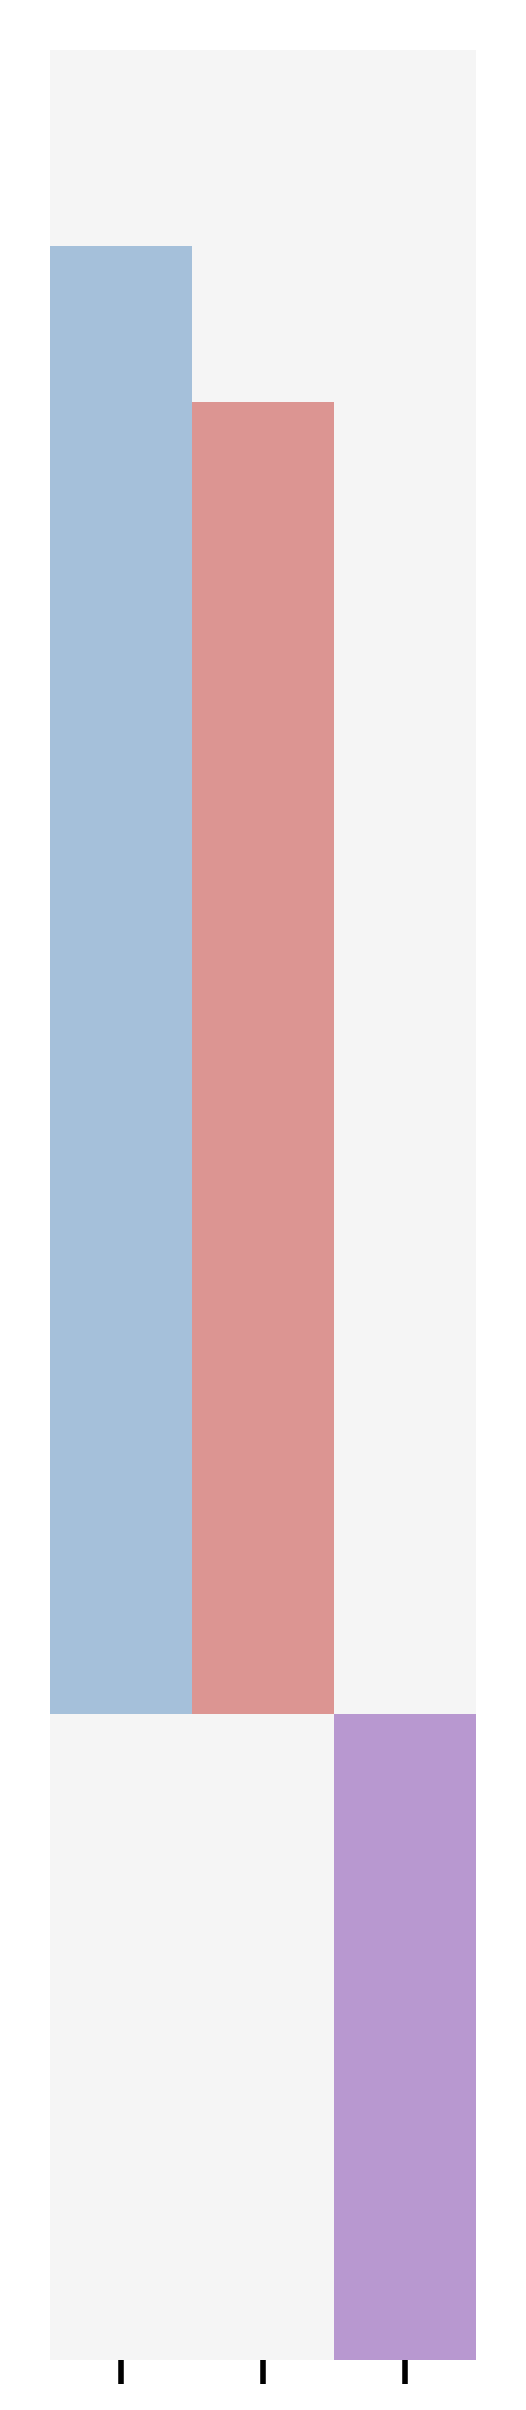

In [23]:
bc46_chr17_ReadLevelVariantInfo_heatmap = bc46_chr17_ReadLevelVariantInfo_heatmap[sorted_variants]
cmap_e = ListedColormap(["whitesmoke", "#A5C0DA", "#A5C0DA", "#DC9592", "#B898D0"])

plt.figure(figsize=(1.1, 6), dpi=500);
ax = sns.heatmap(bc46_chr17_ReadLevelVariantInfo_heatmap.sort_values(sorted_variants[::-1]), 
                 cmap=cmap_e, cbar=False,)
ax.set_yticklabels([]);
ax.set_yticks([]);
ax.set_xticklabels([]);
ax.set_xlabel('');
ax.set_ylabel('');
# ax.set_xticklabels(['Germline', 'Pathogenic A', 'Pathogenic B']);

## barcode61, chr17, TP53

In [24]:
PATH_BAM = '/data01/node200data/18parkky/datasets/data/FGL/FASTQ/AML_TS_Run3_260223_sup/minimap2_out/barcode61.sorted.bam'

variants_of_interest = [['chr17', 7673534, 'C', 'G', 'pathogenic'], 
                        ['chr17', 7674872, 'T', 'C', 'pathogenic'], 
                        ['chr17', 7672958, 'T', 'A', 'germline'], 
                        ['chr17', 7673030, 'C', 'T', 'germline'],
                        ]

variants_of_interest = pd.DataFrame(variants_of_interest, columns=['chrom', 'pos', 'ref', 'alt', 'variant_type'])
bc61_chr17_ReadLevelVariantInfo, bc61_chr17_ReadLevelVariantInfo_organized = getReadLevelVariantInfo(PATH_BAM, variants_of_interest)
bc61_chr17_ReadLevelVariantInfo_organized['isMut'] = bc61_chr17_ReadLevelVariantInfo_organized['read_allele']==bc61_chr17_ReadLevelVariantInfo_organized['alt_allele']
bc61_chr17_ReadLevelVariantInfo['Identifier'] = [ f'{tup.chrom}:{tup.pos}:{tup.ref_allele}>{tup.alt_allele}:{tup.variant_type}' for tup in bc61_chr17_ReadLevelVariantInfo.itertuples() ]
bc61_chr17_ReadLevelVariantInfo_organized['Identifier'] = [ f'{tup.chrom}:{tup.pos}:{tup.ref_allele}>{tup.alt_allele}:{tup.variant_type}' for tup in bc61_chr17_ReadLevelVariantInfo_organized.itertuples() ]

bc61_chr17_ReadLevelVariantInfo_organized.head(4)

,readname,chrom,pos,variant_type,read_allele,ref_allele,alt_allele,isMut,Identifier
0,0a6719e1-e958-4345-a7d0-68ef3b58f1bb,chr17,7673534,pathogenic,G,C,G,True,chr17:7673534:C>G:pathogenic
1,0a6719e1-e958-4345-a7d0-68ef3b58f1bb,chr17,7674872,pathogenic,T,T,C,False,chr17:7674872:T>C:pathogenic
2,0a6719e1-e958-4345-a7d0-68ef3b58f1bb,chr17,7672958,germline,A,T,A,True,chr17:7672958:T>A:germline
3,0a6719e1-e958-4345-a7d0-68ef3b58f1bb,chr17,7673030,germline,T,C,T,True,chr17:7673030:C>T:germline


In [25]:
bc61_chr17_ReadLevelVariantInfo_heatmap = bc61_chr17_ReadLevelVariantInfo_organized.pivot(index='readname', columns='Identifier', values='isMut')

sorted_variants = sorted(set(bc61_chr17_ReadLevelVariantInfo_organized['Identifier']), key=lambda x: ( x.endswith(":pathogenic"), int(x.split(":")[1])))
for idx, variant in enumerate(sorted_variants):
    bc61_chr17_ReadLevelVariantInfo_heatmap[variant] = bc61_chr17_ReadLevelVariantInfo_heatmap[variant].replace({True : idx+1, False: 0})

/tmp/ipykernel_2557740/2192104021.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bc61_chr17_ReadLevelVariantInfo_heatmap[variant] = bc61_chr17_ReadLevelVariantInfo_heatmap[variant].replace({True : idx+1, False: 0})


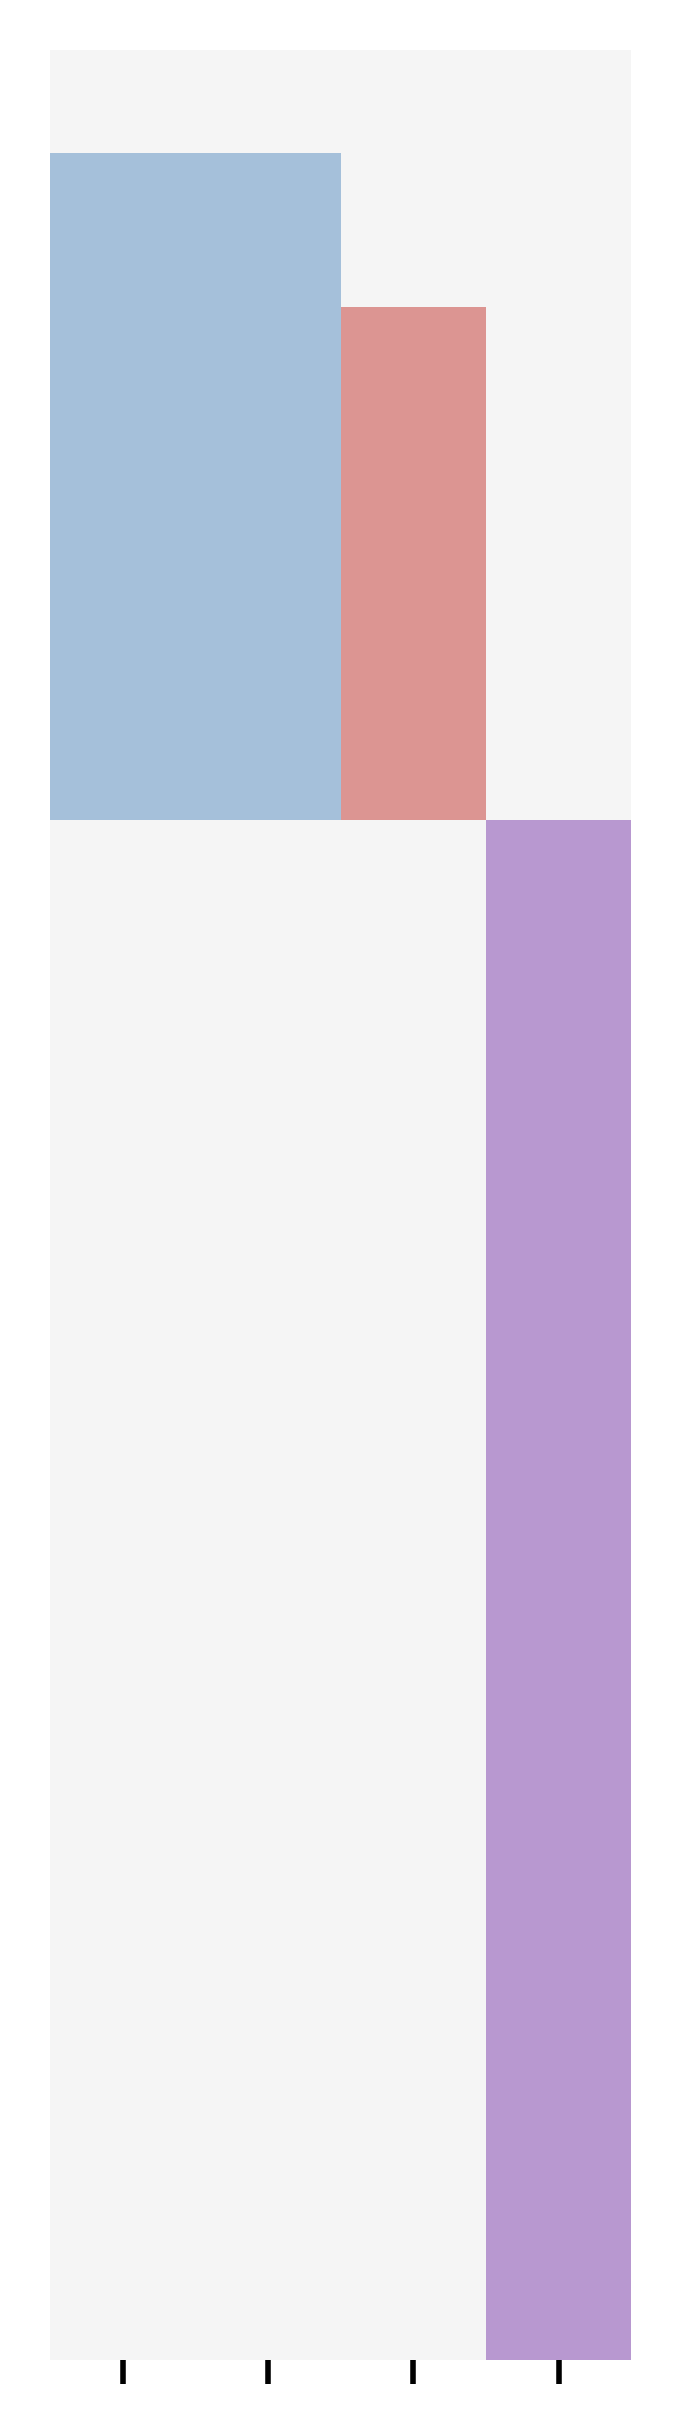

In [26]:
bc61_chr17_ReadLevelVariantInfo_heatmap = bc61_chr17_ReadLevelVariantInfo_heatmap[sorted_variants]
cmap_e = ListedColormap(["whitesmoke", "#A5C0DA", "#A5C0DA", "#DC9592", "#B898D0"])

plt.figure(figsize=(1.5, 6), dpi=500);
ax = sns.heatmap(bc61_chr17_ReadLevelVariantInfo_heatmap.sort_values(sorted_variants[::-1]), 
                 cmap=cmap_e, cbar=False,)
ax.set_yticklabels([]);
ax.set_yticks([]);
ax.set_xticklabels([]);
ax.set_xlabel('');
ax.set_ylabel('');
# ax.set_xticklabels(['Germline', 'Pathogenic A', 'Pathogenic B']);